# Beavers and wildfire: does fire happen less where beavers are recorded?

Uses the tables made by the prep scripts (run from the `prep/` folder):

```
python prep_cells.py ..\NASAdata --land ..\site\public\geo_files\NA.geojson --cell-size 10 25 50 --out analysis_data --months 4-10
python animal_cells.py --grid analysis_data/50km analysis_data/25km analysis_data/10km --csv <gbif.csv> --label beaver --since 2015
```

All analyses use equal-area grid cells (North America Albers). Recovery in the years after a fire is in `recovery_cells.ipynb`.

| Question | Section | Main number |
|---|---|---|
| Do cells with beaver records burn less often? | 3b Part 1 | odds ratio of `beaver_present` |
| When a cell burns, does less of it burn? | 3b Part 2 | `times` of `beaver_present` |
| Does vegetation drop less in burned cells? | 4 | coefficient of `beaver_present` |
| Is it real or just *where people look*? | **6** robustness | odds ratios after regional comparison / surveyed area |
| Same at 10, 25, 50 km? | 7 | table |
| Same in other fire seasons? | 8 | table + pooled model |
| One chart with everything | 9 | odds-ratio chart |

**Read before interpreting.** GBIF records show where beavers were *observed*, not where they *live*; records cluster where
people are, while big fires often burn in remote areas. Section 6 tests how much of the result survives when we compare
cells within the same region and only where people actually record beavers. Report results as **associations**.

In [ ]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy import stats
from scipy import ndimage as ndi
import statsmodels.formula.api as smf

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

## Settings

In [ ]:
DATA = Path("analysis_data")
GRID = "50km"                     # main grid: "10km", "25km" or "50km"
GRIDS = ["10km", "25km", "50km"]  # section 7
ANIMAL = "beaver"                 # file name in analysis_data/<grid>/animals/

YEAR = 2023                       # fire season to analyse (2023 = Canada's record fire year)
YEARS = [2017, 2018, 2021, 2023]  # section 8: big fire seasons to compare
NDVI_MONTH = 8                    # August NDVI: YEAR vs the year before (same month -> seasonal cycle cancels)

MIN_LAND = 0.3                    # drop cells that are mostly ocean
MIN_VALID = 0.5                   # drop cells with too little valid NDVI (clouds, snow, water)
MIN_NDVI_PRE = 0.3                # drop sparsely vegetated cells (desert, tundra, rock) - little to burn
MIN_BURN_FRAC = 0.01              # a cell "burned" if >= 1% of its land burned
CLEAN = 0.005                     # "no fire" = less than 0.5% burned
LAT_BAND = 2                      # degrees: unburned cells in the same band give the normal NDVI change
BLOCK_KM = 500                    # region size for the within-region comparison (section 6a)
SURVEY_KM = 100                   # "surveyed" = a beaver record within this distance (section 6b)

## 1. Load and build one row per cell

For the fire season of `YEAR` (April–October), each cell gets:
- `burned_frac` / `burned`: share of land burned in the season / burned at least 1%
- `burn_early` (April–July) and `burn_late` (August–October): fires before vs after the August NDVI
- `burn_prev`: burned share in the previous season (affects the "before" NDVI)
- `ndvi_pre` / `ndvi_post`: August NDVI of the year before / of `YEAR`
- `ndvi_change_anom`: NDVI change minus the median change of cells at the same latitude that did not burn in either year
  (removes weather differences between years)
- `beaver_present` (at least one record since 2015), `block` (500 km region), `surveyed` (beaver record within 100 km)

In [ ]:
def surveyed_flag(cells, meta, present):
    """1 where a beaver record exists within SURVEY_KM (square window on the grid)."""
    km = meta["cell_size_m"] / 1000
    grid = np.zeros((meta["height"], meta["width"]), bool)
    grid[cells["row"], cells["col"]] = present
    r = int(np.ceil(SURVEY_KM / km))
    near = ndi.maximum_filter(grid, size=2 * r + 1)
    return near[cells["row"], cells["col"]].astype(int)


def load_cells(grid, year):
    d = DATA / grid
    meta = json.loads((d / "meta.json").read_text())
    cells = pd.read_parquet(d / "cells.parquet")
    animal = pd.read_parquet(d / "animals" / f"{ANIMAL}.parquet")[["cell_id", "n"]]
    season = [m for m in meta["burn_months"] if m.startswith(f"{year}-")]
    prev = [m for m in meta["burn_months"] if m.startswith(f"{year - 1}-")]
    pre_m, post_m = f"{year - 1}-{NDVI_MONTH:02d}", f"{year}-{NDVI_MONTH:02d}"
    if not season:
        raise ValueError(f"No burned-area data for {year} in {grid}")
    for m in (pre_m, post_m):
        if m not in meta["ndvi_months"]:
            raise ValueError(f"{m} has no NDVI in {grid}")
    # read only the months needed (the 10 km table has tens of millions of rows)
    panel = pd.read_parquet(d / "panel.parquet", filters=[("month", "in", season + prev + [pre_m, post_m])])

    def burned_share(months):
        p = panel[panel["month"].isin(months)]
        return p.groupby("cell_id")["burned_frac"].sum() if len(p) else pd.Series(dtype=float)

    df = cells.merge(animal.rename(columns={"n": "beaver_n"}), on="cell_id", how="left")
    df["beaver_n"] = df["beaver_n"].fillna(0).astype(int)
    df["beaver_present"] = (df["beaver_n"] > 0).astype(int)
    df["log_beaver"] = np.log1p(df["beaver_n"])
    df["surveyed"] = surveyed_flag(df, meta, df["beaver_present"].values > 0)
    km = meta["cell_size_m"] / 1000
    df["block"] = ((df["row"] * km) // BLOCK_KM).astype(int) * 10000 + ((df["col"] * km) // BLOCK_KM).astype(int)

    df["burned_frac"] = df["cell_id"].map(burned_share(season))
    df["burn_early"] = df["cell_id"].map(burned_share([m for m in season if int(m[5:]) < NDVI_MONTH])).fillna(0)
    df["burn_late"] = df["cell_id"].map(burned_share([m for m in season if int(m[5:]) >= NDVI_MONTH])).fillna(0)
    df["burn_prev"] = df["cell_id"].map(burned_share(prev)).fillna(0)
    df["burned"] = (df["burned_frac"] >= MIN_BURN_FRAC).astype(int)

    ndvi = panel.pivot(index="cell_id", columns="month", values="ndvi_mean")
    valid = panel.pivot(index="cell_id", columns="month", values="ndvi_valid_frac")
    df["ndvi_pre"] = df["cell_id"].map(ndvi[pre_m])
    df["ndvi_post"] = df["cell_id"].map(ndvi[post_m])
    df["ndvi_valid"] = np.fmin(df["cell_id"].map(valid[pre_m]), df["cell_id"].map(valid[post_m]))

    df = df[(df["land_frac"] >= MIN_LAND) & (df["ndvi_valid"] >= MIN_VALID) & (df["ndvi_pre"] >= MIN_NDVI_PRE)]
    df = df.dropna(subset=["burned_frac", "ndvi_pre", "ndvi_post"]).copy()

    # NDVI change relative to cells at the same latitude that did not burn this season or the last
    df["ndvi_change"] = df["ndvi_post"] - df["ndvi_pre"]
    df["lat_band"] = (df["lat"] // LAT_BAND) * LAT_BAND
    clean = (df["burned_frac"] < CLEAN) & (df["burn_prev"] < CLEAN)
    normal = df[clean].groupby("lat_band")["ndvi_change"].median()
    df["ndvi_change_anom"] = df["ndvi_change"] - df["lat_band"].map(normal)
    for c in ("ndvi_pre", "lat", "lon"):
        df[c + "_z"] = (df[c] - df[c].mean()) / df[c].std()
    df.attrs.update(grid=grid, year=year, season=season, pre=pre_m, post=post_m)
    return df


df = load_cells(GRID, YEAR)
print(f"{GRID}, {YEAR}: {len(df):,} cells | burned {df['burned'].sum():,} | "
      f"with {ANIMAL} records {df['beaver_present'].sum():,} | surveyed {df['surveyed'].sum():,} | "
      f"regions {df['block'].nunique()}")
df.describe()[["burned_frac", "burn_early", "burn_late", "ndvi_pre", "ndvi_post", "ndvi_change_anom", "beaver_n"]].round(3)

50km, 2023: 6,853 cells | burned 579 | with beaver records 2,572 | surveyed 5,222 | regions 123


,burned_frac,burn_early,burn_late,ndvi_pre,ndvi_post,ndvi_change_anom,beaver_n
count,6853.000,6853.000,6853.000,6853.000,6853.000,6853.000,6853.000
mean,0.009,0.006,0.003,0.645,0.638,-0.002,7.719
std,0.047,0.037,0.023,0.154,0.154,0.043,42.836
min,0.000,0.000,0.000,0.300,-0.005,-0.300,0.000
25%,0.000,0.000,0.000,0.548,0.541,-0.021,0.000
50%,0.000,0.000,0.000,0.682,0.669,-0.002,0.000
75%,0.000,0.000,0.000,0.766,0.759,0.018,2.000
max,0.843,0.843,0.741,0.893,0.893,0.254,1657.000


## 2. Maps

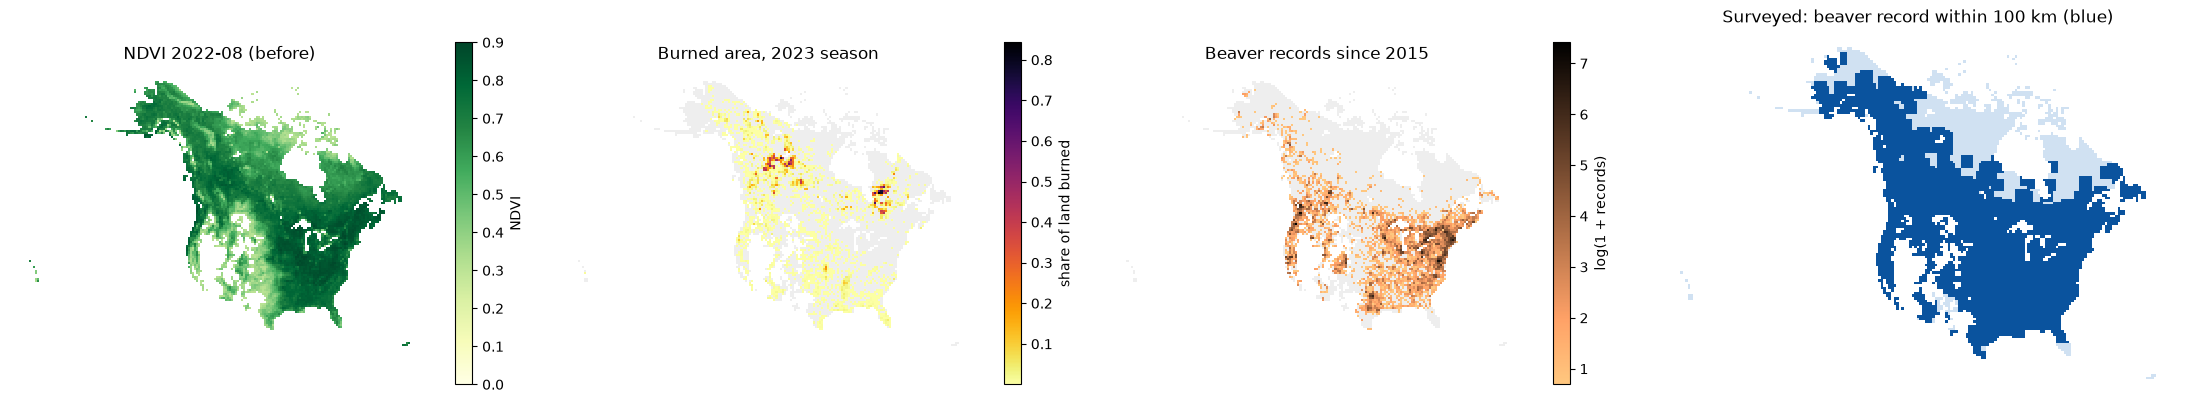

In [ ]:
grid_geo = gpd.read_file(DATA / GRID / "grid.gpkg")[["cell_id", "geometry"]]
g = grid_geo.merge(df, on="cell_id")

fig, ax = plt.subplots(1, 4, figsize=(22, 6))
g.plot(ax=ax[0], column="ndvi_pre", cmap="YlGn", vmin=0, vmax=0.9, legend=True,
       legend_kwds={"shrink": 0.6, "label": "NDVI"})
ax[0].set_title(f"NDVI {df.attrs['pre']} (before)")
g.plot(ax=ax[1], color="#eeeeee")
g[g["burned_frac"] > 0].plot(ax=ax[1], column="burned_frac", cmap="inferno_r", legend=True,
                             legend_kwds={"shrink": 0.6, "label": "share of land burned"})
ax[1].set_title(f"Burned area, {YEAR} season")
g.plot(ax=ax[2], color="#eeeeee")
g[g["beaver_n"] > 0].plot(ax=ax[2], column="log_beaver", cmap="copper_r", legend=True,
                          legend_kwds={"shrink": 0.6, "label": "log(1 + records)"})
ax[2].set_title(f"{ANIMAL.capitalize()} records since 2015")
g.plot(ax=ax[3], column="surveyed", cmap="Blues", vmin=-0.3, vmax=1.2)
ax[3].set_title(f"Surveyed: {ANIMAL} record within {SURVEY_KM} km (blue)")
for a in ax:
    a.set_axis_off()
plt.tight_layout()
plt.show()

## 3. Beavers and burned area

**3a. Spearman correlation** (rank-based; most cells have 0 burned).

In [ ]:
def spearman(x, y):
    r, p = stats.spearmanr(x, y)
    return round(r, 3), p

pd.DataFrame({
    "all cells: beaver records vs burned share": spearman(df["log_beaver"], df["burned_frac"]),
    "burned cells only": spearman(df.loc[df["burned"] == 1, "log_beaver"], df.loc[df["burned"] == 1, "burned_frac"]),
}, index=["rho", "p"]).T

,rho,p
all cells: beaver records vs burned share,-0.051,0.000026
burned cells only,-0.183,0.000009


**3b. Two-part model**, controls: vegetation (`ndvi_pre`), latitude, longitude.
- **Part 1** (logistic regression, all cells): did the cell burn? Odds ratio < 1 = cells with beaver records burned *less often*.
- **Part 2** (linear regression on log burned share, burned cells): when it burned, how much? `times` < 1 = *less area*.

In [ ]:
COVARS = "beaver_present + ndvi_pre_z + lat_z + lon_z"


def or_table(res, var=None):
    ci = res.conf_int()
    t = pd.DataFrame({"odds_ratio": np.exp(res.params), "ci_low": np.exp(ci[0]), "ci_high": np.exp(ci[1]), "p": res.pvalues})
    return t.round(3) if var is None else t.loc[var]


def two_part(d):
    part1 = smf.logit(f"burned ~ {COVARS}", data=d).fit(disp=0, cov_type="HC3")
    b = d[d["burned"] == 1].assign(log_burn=lambda x: np.log(x["burned_frac"]))
    part2 = smf.ols(f"log_burn ~ {COVARS}", data=b).fit(cov_type="HC3") if len(b) >= 20 else None
    return part1, part2


part1, part2 = two_part(df)
print("Part 1: did the cell burn?  (odds ratios, 95% CI)")
display(or_table(part1))
if part2 is not None:
    print("Part 2: how much burned (burned cells)?  times = multiplicative change in burned share")
    display(or_table(part2).rename(columns={"odds_ratio": "times"}))

Part 1: did the cell burn?  (odds ratios, 95% CI)


,odds_ratio,ci_low,ci_high,p
Intercept,0.114,0.102,0.127,0.000
beaver_present,0.394,0.309,0.503,0.000
ndvi_pre_z,1.678,1.518,1.853,0.000
lat_z,1.086,0.964,1.225,0.175
lon_z,0.931,0.862,1.005,0.067


Part 2: how much burned (burned cells)?  times = multiplicative change in burned share


,times,ci_low,ci_high,p
Intercept,0.046,0.042,0.050,0.000
beaver_present,0.980,0.804,1.194,0.839
ndvi_pre_z,1.076,0.958,1.209,0.214
lat_z,1.697,1.540,1.869,0.000
lon_z,1.375,1.209,1.564,0.000


**3c. Spatial autocorrelation (Moran's I)** of the Part 1 residuals (8 neighbours, 999 shuffles).
Clearly positive = neighbouring cells are alike and the p-values above are too optimistic; rely on sections 6–8.

In [ ]:
def morans_i(values, rows, cols, permutations=999, seed=0):
    z = np.asarray(values, float) - np.mean(values)
    pos = {(r, c): i for i, (r, c) in enumerate(zip(rows, cols))}
    pairs = [(i, pos[(r + dr, c + dc)]) for (r, c), i in pos.items()
             for dr in (-1, 0, 1) for dc in (-1, 0, 1) if (dr or dc) and (r + dr, c + dc) in pos]
    a, b = np.array(pairs).T
    stat = lambda v: len(v) / len(a) * np.sum(v[a] * v[b]) / np.sum(v * v)
    obs = stat(z)
    rng = np.random.default_rng(seed)
    sims = np.array([stat(rng.permutation(z)) for _ in range(permutations)])
    return obs, (np.sum(np.abs(sims) >= abs(obs)) + 1) / (permutations + 1)


I, p = morans_i(part1.resid_pearson, df["row"], df["col"])
print(f"Moran's I of Part 1 residuals: {I:.3f} (p = {p:.3f})")

Moran's I of Part 1 residuals: 0.348 (p = 0.001)


## 4. Vegetation resistance: does NDVI drop less in burned cells with beaver records?

Only cells whose fire happened **before** the August NDVI (April–July), with **no** August–October fire and **no** fire
in the previous season, so the before/after NDVI is clean. Compared at the same burned share (bigger fires drop NDVI more).

cells: 227 (with beaver records 38, without 189)
median extra NDVI change  with: -0.019   without: -0.023   Mann-Whitney p = 0.18


,coef,ci_low,ci_high,p
Intercept,0.0422,-0.0611,0.1455,0.4237
beaver_present,0.0121,0.0019,0.0223,0.0202
burn_early,-0.2246,-0.2553,-0.1940,0.0000
ndvi_pre,0.0292,-0.0402,0.0986,0.4092
lat,0.0000,-0.0015,0.0015,0.9868
lon,0.0008,0.0005,0.0010,0.0000


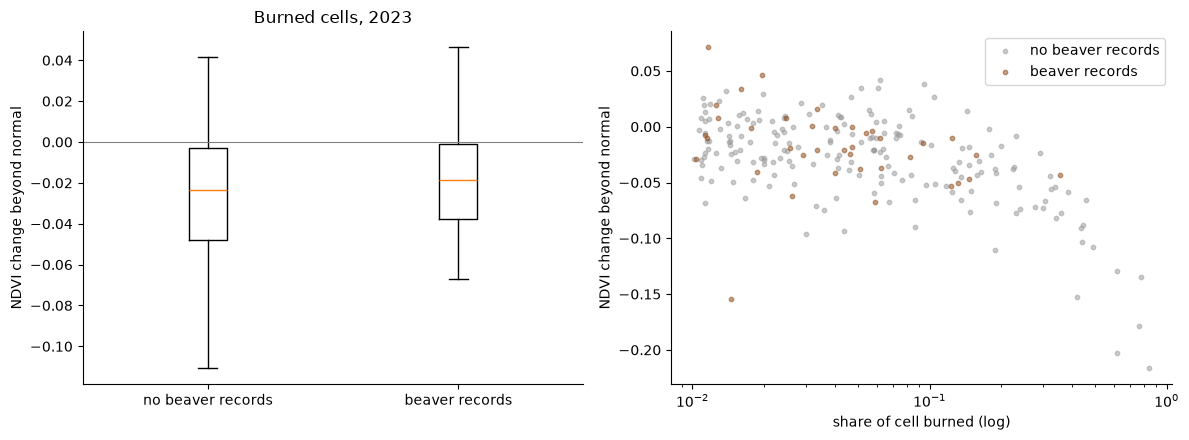

In [ ]:
def ndvi_set(d):
    return d[(d["burn_early"] >= MIN_BURN_FRAC) & (d["burn_late"] < CLEAN) & (d["burn_prev"] < CLEAN)]


def ndvi_model(d):
    s = ndvi_set(d)
    if (s["beaver_present"] == 1).sum() < 5 or (s["beaver_present"] == 0).sum() < 5:
        return None, s
    return smf.ols("ndvi_change_anom ~ beaver_present + burn_early + ndvi_pre + lat + lon", data=s).fit(cov_type="HC3"), s


m, burned_ndvi = ndvi_model(df)
with_b = burned_ndvi.loc[burned_ndvi["beaver_present"] == 1, "ndvi_change_anom"]
without_b = burned_ndvi.loc[burned_ndvi["beaver_present"] == 0, "ndvi_change_anom"]
print(f"cells: {len(burned_ndvi):,} (with {ANIMAL} records {len(with_b):,}, without {len(without_b):,})")
if m is not None:
    u, p_mw = stats.mannwhitneyu(with_b, without_b, alternative="two-sided")
    print(f"median extra NDVI change  with: {with_b.median():+.3f}   without: {without_b.median():+.3f}   Mann-Whitney p = {p_mw:.3g}")
    ci = m.conf_int()
    display(pd.DataFrame({"coef": m.params, "ci_low": ci[0], "ci_high": ci[1], "p": m.pvalues}).round(4))

    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].boxplot([without_b, with_b], showfliers=False)
    ax[0].set_xticks([1, 2], [f"no {ANIMAL} records", f"{ANIMAL} records"])
    ax[0].axhline(0, color="grey", lw=0.8)
    ax[0].set_ylabel("NDVI change beyond normal")
    ax[0].set_title(f"Burned cells, {YEAR}")
    for present, color in ((0, "#999999"), (1, "#8b4513")):
        s = burned_ndvi[burned_ndvi["beaver_present"] == present]
        ax[1].scatter(s["burn_early"], s["ndvi_change_anom"], s=10, alpha=0.5, color=color,
                      label=f"{ANIMAL} records" if present else f"no {ANIMAL} records")
    ax[1].set_xscale("log")
    ax[1].set_xlabel("share of cell burned (log)")
    ax[1].set_ylabel("NDVI change beyond normal")
    ax[1].legend()
    plt.tight_layout()
    plt.show()
else:
    print("Not enough cells in one of the groups.")

## 5. Burned share by beaver presence (burned cells)

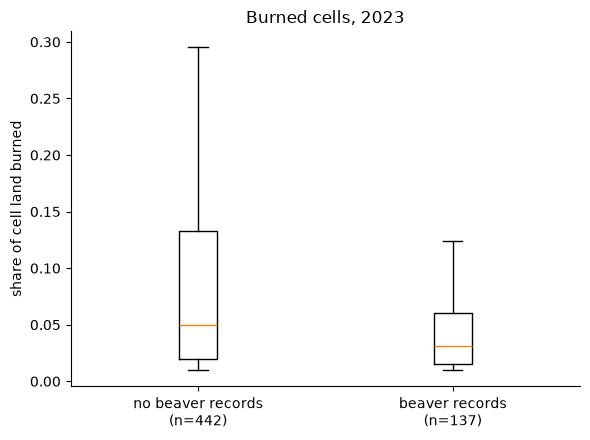

In [ ]:
burned = df[df["burned"] == 1]
data = [burned.loc[burned["beaver_present"] == k, "burned_frac"] for k in (0, 1)]
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.boxplot(data, showfliers=False)
ax.set_xticks([1, 2], [f"no {ANIMAL} records\n(n={len(data[0])})", f"{ANIMAL} records\n(n={len(data[1])})"])
ax.set_ylabel("share of cell land burned")
ax.set_title(f"Burned cells, {YEAR}")
plt.tight_layout()
plt.show()

## 6. Robustness: is it beavers, or where people look?

Three versions of the Part 1 odds ratio (did the cell burn?):

| Check | What it compares | Why |
|---|---|---|
| **latitude/longitude** | all cells, controls are straight-line trends | baseline from section 3b |
| **6a within region** | only cells **in the same 500 km region** (one intercept per region; standard errors clustered by region) | removes broad differences in fire climate and remoteness between regions |
| **6b surveyed area** | only cells with a beaver record **within 100 km** | removes remote areas where nobody records beavers at all |
| **6c both** | surveyed cells, within region | strictest |

If the odds ratio stays well below 1 in 6a–6c, the association is more believable. If it moves to ~1, the first result
was mostly about *where people observe*, which is also a valid finding.

In [ ]:
def within_region_or(d, max_controls=10, max_rows=60_000, seed=0):
    """Logistic regression with one intercept per region: cells are only compared within their region.

    Standard errors are clustered by region (cells in a region are not independent). For large data
    (10 km), all burned cells are kept plus a random sample of unburned cells per region (up to
    `max_controls` per burned cell); with region intercepts this leaves the odds ratio unbiased.
    """
    keep = d.groupby("block")["burned"].transform(lambda s: 0 < s.sum() < len(s))   # regions with burned AND unburned cells
    keep &= d.groupby("block")["beaver_present"].transform(lambda s: 0 < s.sum() < len(s))
    s = d[keep]
    if s["burned"].sum() < 10 or s["block"].nunique() < 2:
        return None
    sampled = len(s) > max_rows
    if sampled:
        rng = np.random.default_rng(seed)
        parts = []
        for _, grp in s.groupby("block"):
            cases, ctrl = grp[grp["burned"] == 1], grp[grp["burned"] == 0]
            k = min(len(ctrl), max_controls * len(cases))
            parts += [cases, ctrl.iloc[rng.choice(len(ctrl), k, replace=False)]]
        s = pd.concat(parts)
    try:
        res = smf.logit("burned ~ beaver_present + ndvi_pre_z + C(block)", data=s).fit(
            disp=0, maxiter=200, cov_type="cluster", cov_kwds={"groups": pd.factorize(s["block"])[0]})
    except Exception as e:                       # e.g. perfect separation in a tiny sample
        print("within-region model failed:", e)
        return None
    b, se = res.params["beaver_present"], res.bse["beaver_present"]
    return {"odds_ratio": np.exp(b), "ci_low": np.exp(b - 1.96 * se), "ci_high": np.exp(b + 1.96 * se),
            "p": res.pvalues["beaver_present"], "cells": len(s), "burned": int(s["burned"].sum()),
            "regions": s["block"].nunique(), "sampled": sampled}


def latlon_or(d):
    if d["burned"].sum() < 10 or d["beaver_present"].nunique() < 2:
        return None
    res = smf.logit(f"burned ~ {COVARS}", data=d).fit(disp=0, cov_type="HC3")
    r = or_table(res, "beaver_present").to_dict()
    return r | {"cells": len(d), "burned": int(d["burned"].sum())}


def fire_checks(d):
    sv = d[d["surveyed"] == 1]
    rows = {"lat/lon controls (3b)": latlon_or(d),
            "6a within region": within_region_or(d),
            "6b surveyed area": latlon_or(sv),
            "6c surveyed + within region": within_region_or(sv)}
    return pd.DataFrame({k: v for k, v in rows.items() if v is not None}).T


checks = fire_checks(df)
checks.round(3)

,odds_ratio,ci_low,ci_high,p,cells,burned,regions,sampled
lat/lon controls (3b),0.394236,0.309157,0.50273,0.0,6853.0,579.0,NaN,NaN
6a within region,0.667784,0.487135,0.915424,0.012104,4166,562,52,False
6b surveyed area,0.481881,0.378157,0.614055,0.0,5222.0,459.0,NaN,NaN
6c surveyed + within region,0.664354,0.483588,0.912689,0.011608,3334,456,48,False


## 7. Same checks at 10, 25 and 50 km

A relationship that keeps its direction at every cell size is far more convincing (modifiable areal unit problem).

In [ ]:
def summary_row(d):
    c = fire_checks(d)
    p1, p2 = two_part(d)
    m, s = ndvi_model(d)
    row = {"cells": len(d), "burned": int(d["burned"].sum()), "with_records": int(d["beaver_present"].sum())}
    for name, short in (("lat/lon controls (3b)", "OR_latlon"), ("6a within region", "OR_region"),
                        ("6b surveyed area", "OR_surveyed"), ("6c surveyed + within region", "OR_strict")):
        if name in c.index:
            row[short] = c.loc[name, "odds_ratio"]
            row[short + "_p"] = c.loc[name, "p"]
    if p2 is not None:
        row["burned_share_times"] = np.exp(p2.params["beaver_present"])
        row["burned_share_p"] = p2.pvalues["beaver_present"]
    if m is not None:
        row["ndvi_effect"] = m.params["beaver_present"]
        row["ndvi_effect_p"] = m.pvalues["beaver_present"]
    return row


by_grid = pd.DataFrame({gname: summary_row(load_cells(gname, YEAR)) for gname in GRIDS}).T
by_grid.round(4)

,cells,burned,with_records,OR_latlon,OR_latlon_p,OR_region,OR_region_p,OR_surveyed,OR_surveyed_p,OR_strict,OR_strict_p,burned_share_times,burned_share_p,ndvi_effect,ndvi_effect_p
10km,165764.0,6377.0,10791.0,0.3085,0.0,0.5848,0.0005,0.3480,0.0,0.5851,0.0006,0.8787,0.1724,-0.0033,0.6668
25km,26890.0,1664.0,5375.0,0.3441,0.0,0.5550,0.0000,0.3988,0.0,0.5583,0.0000,0.8000,0.0119,0.0024,0.6863
50km,6853.0,579.0,2572.0,0.3942,0.0,0.6678,0.0121,0.4819,0.0,0.6644,0.0116,0.9797,0.8392,0.0121,0.0202


## 8. Same checks in other fire seasons, and all seasons pooled

Each big season separately (at `GRID`), then a **pooled** within-region model over all `YEARS`: cells are compared only
with cells in the same region **and** the same year.

In [ ]:
by_year, pooled = {}, []
for y in YEARS:
    try:
        d = load_cells(GRID, y)
    except ValueError as e:
        print(f"skip {y}: {e}")
        continue
    by_year[y] = summary_row(d)
    pooled.append(d.assign(year=y, block=d["block"] * 10000 + y))     # region x year groups
by_year = pd.DataFrame(by_year).T
display(by_year.round(4))

if pooled:
    pool = pd.concat(pooled, ignore_index=True)
    for name, data in (("pooled, within region x year", pool), ("pooled, surveyed + within region x year", pool[pool["surveyed"] == 1])):
        r = within_region_or(data)
        if r:
            print(f"{name}: OR {r['odds_ratio']:.3f} (95% CI {r['ci_low']:.3f}-{r['ci_high']:.3f}), p = {r['p']:.3g}, "
                  f"{r['cells']:,} cell-years")

,cells,burned,with_records,OR_latlon,OR_latlon_p,OR_region,OR_region_p,OR_surveyed,OR_surveyed_p,OR_strict,OR_strict_p,burned_share_times,burned_share_p,ndvi_effect,ndvi_effect_p
2017,6833.0,319.0,2578.0,0.7864,0.0947,0.6486,0.0105,0.7705,0.0643,0.6547,0.0115,0.9559,0.6859,-0.0102,0.4216
2018,6838.0,316.0,2587.0,1.2398,0.1238,1.1089,0.5024,1.2109,0.1635,1.1110,0.5009,0.9711,0.7661,-0.0069,0.4169
2021,6825.0,380.0,2565.0,1.0945,0.4846,1.1468,0.3812,1.0642,0.6206,1.1184,0.4740,1.0215,0.8387,-0.0121,0.2200
2023,6853.0,579.0,2572.0,0.3942,0.0000,0.6678,0.0121,0.4819,0.0000,0.6644,0.0116,0.9797,0.8392,0.0121,0.0202


pooled, within region x year: OR 0.859 (95% CI 0.733-1.008), p = 0.0621, 15,991 cell-years
pooled, surveyed + within region x year: OR 0.857 (95% CI 0.731-1.006), p = 0.0587, 13,236 cell-years


In [ ]:
rows, pooled_rows = {}, {}
for gname in GRIDS:
    stack = []
    for y in YEARS:
        try:
            d = load_cells(gname, y)
        except ValueError as e:
            print(f"skip {gname} {y}: {e}")
            continue
        rows[(gname, y)] = summary_row(d)
        stack.append(d.assign(block=d["block"] * 10000 + y))     # region x year groups
    if stack:
        pool = pd.concat(stack, ignore_index=True)
        for name, data in (("within region x year", pool),
                           ("surveyed + within region x year", pool[pool["surveyed"] == 1])):
            r = within_region_or(data)
            if r:
                pooled_rows[(gname, name)] = r

display(pd.DataFrame(rows).T[["burned", "OR_latlon", "OR_region", "OR_region_p", "OR_strict", "OR_strict_p",
                              "burned_share_times", "ndvi_effect", "ndvi_effect_p"]].round(3))
display(pd.DataFrame(pooled_rows).T[["odds_ratio", "ci_low", "ci_high", "p", "cells", "burned"]].round(3))

burned  OR_latlon  OR_region  OR_region_p  OR_strict  OR_strict_p  burned_share_times  ndvi_effect  ndvi_effect_p
10km 2017  3391.0      0.502      0.616        0.002      0.611        0.001               0.881       -0.006          0.350
     2018  3132.0      0.635      0.740        0.002      0.716        0.000               0.829        0.001          0.887
     2021  3943.0      0.661      0.818        0.091      0.805        0.065               0.872       -0.003          0.520
     2023  6377.0      0.309      0.585        0.000      0.585        0.001               0.879       -0.003          0.667
25km 2017   932.0      0.750      0.792        0.044      0.797        0.048               0.779       -0.026          0.002
     2018   866.0      0.716      0.722        0.001      0.719        0.001               0.993       -0.007          0.401
     2021  1047.0      0.754      0.868        0.305      0.856        0.271               1.006       -0.009          0.188
     2023  1664.0      0.344      0.555        0.000      0.558        0.000               0.800        0.002          0.686
50km 2017   319.0      0.786      0.649        0.011      0.655        0.011               0.956       -0.010          0.422
     2018   316.0      1.240      1.109        0.502      1.111        0.501               0.971       -0.007          0.417
     2021   380.0      1.095      1.147        0.381      1.118        0.474               1.022       -0.012          0.220
     2023   579.0      0.394      0.668        0.012      0.664        0.012               0.980        0.012          0.020

odds_ratio    ci_low   ci_high         p   cells burned
10km within region x year              0.675913   0.59452  0.768449       0.0  162021  16250
     surveyed + within region x year   0.689865  0.604694  0.787033       0.0  139044  13983
25km within region x year              0.721656  0.638208  0.816016       0.0   36339   4342
     surveyed + within region x year   0.726334  0.642165  0.821534       0.0   31593   3743
50km within region x year              0.859334  0.732816  1.007695  0.062089   15991   1534
     surveyed + within region x year   0.857129  0.730513   1.00569  0.058702   13236   1354

## 9. Everything in one chart

Odds ratio of burning for cells with beaver records (95% CI). Left of the dashed line = burned less often.
Points that stay left of 1 after the regional and surveyed-area checks, at every cell size and in every season, are the strongest evidence.

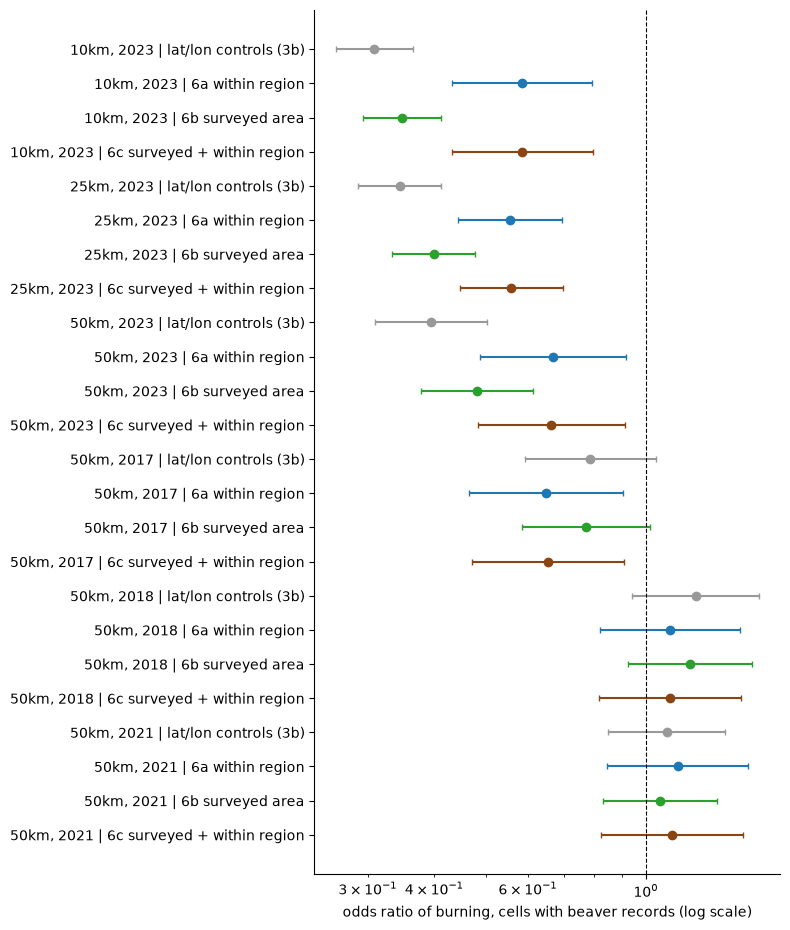

In [ ]:
rows = []
for gname in GRIDS:
    c = fire_checks(load_cells(gname, YEAR))
    rows += [(f"{gname}, {YEAR}", k, *c.loc[k, ["odds_ratio", "ci_low", "ci_high"]]) for k in c.index]
for y in by_year.index:
    if y == YEAR:
        continue
    c = fire_checks(load_cells(GRID, y))
    rows += [(f"{GRID}, {y}", k, *c.loc[k, ["odds_ratio", "ci_low", "ci_high"]]) for k in c.index]
fp = pd.DataFrame(rows, columns=["set", "check", "or", "lo", "hi"])

colors = {"lat/lon controls (3b)": "#999999", "6a within region": "#1f77b4",
          "6b surveyed area": "#2ca02c", "6c surveyed + within region": "#8b4513"}
fig, ax = plt.subplots(figsize=(8, 0.35 * len(fp) + 1))
for i, r in fp.iloc[::-1].reset_index(drop=True).iterrows():
    ax.errorbar(r["or"], i, xerr=[[r["or"] - r["lo"]], [r["hi"] - r["or"]]], fmt="o", color=colors[r["check"]], capsize=2)
ax.set_yticks(range(len(fp)), (fp["set"] + " | " + fp["check"]).iloc[::-1])
ax.axvline(1, color="black", ls="--", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel(f"odds ratio of burning, cells with {ANIMAL} records (log scale)")
plt.tight_layout()
plt.show()

## 10. NDVI timelapse (optional)

Mean NDVI per cell for each month of `YEAR`, saved as a GIF.

In [ ]:
from PIL import Image
import io

meta = json.loads((DATA / GRID / "meta.json").read_text())
months = [m for m in meta["ndvi_months"] if m.startswith(str(YEAR))]
panel = pd.read_parquet(DATA / GRID / "panel.parquet", columns=["cell_id", "month", "ndvi_mean"],
                        filters=[("month", "in", months)])
frames = []
for m in months:
    gm = grid_geo.merge(panel[panel["month"] == m][["cell_id", "ndvi_mean"]], on="cell_id")
    fig, ax = plt.subplots(figsize=(9, 7))
    gm.plot(ax=ax, column="ndvi_mean", cmap="YlGn", vmin=0, vmax=0.9, legend=True,
            legend_kwds={"shrink": 0.6, "label": "NDVI"}, missing_kwds={"color": "#f2f2f2"})
    ax.set_title(f"Mean NDVI per {GRID} cell, {m}")
    ax.set_axis_off()
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=80, facecolor="white")
    plt.close(fig)
    frames.append(Image.open(buf).convert("RGB"))
frames[0].save(f"ndvi_timelapse_{GRID}_{YEAR}.gif", save_all=True, append_images=frames[1:], duration=900, loop=0)
print(f"saved ndvi_timelapse_{GRID}_{YEAR}.gif ({len(frames)} months)")

saved ndvi_timelapse_50km_2023.gif (7 months)


## 11. Writing it up

- Lead with the **strictest** check that still has enough cells (6c or 6a), not the first odds ratio.
- Show the chart from section 9: consistency across checks, cell sizes and seasons is the argument.
- Part 2 (burned share) and section 4 (NDVI) tell you whether there is any sign of fires being *smaller* or *less damaging*
  near beavers, not just *less frequent*.
- Wording: *"Cells with beaver records burned less often (OR = …), and this held / weakened when comparing within regions
  and only in surveyed areas"* — not *"beavers prevent fire"*.
- Limitations: GBIF observation bias (partly addressed in section 6), 1 km NDVI mixes riparian strips with surrounding
  forest, MCD64A1 misses small fires and includes farm burns, beaver records are counted over all years since 2015.